In [29]:
!find / -name "netflix_customer_churn.csv" 2>/dev/null

/kaggle/input/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics/netflix_customer_churn.csv


In [30]:
import pandas as pd

path = "/kaggle/input/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics/netflix_customer_churn.csv"  
df = pd.read_csv(path)
print(df.shape)
df.info()
print(df.isna().sum())
print(df.duplicated().sum(), df["customer_id"].duplicated().sum())
print(df["churned"].mean())

(5000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: float64(3), int64(4), obje

In [31]:
# 1. Диапазоны числовых столбцов
print(df.describe().round(2))

# 2. Категориальные столбцы: какие значения и сколько их
for c in ["gender", "subscription_type", "region", "device", "payment_method", "favorite_genre"]:
    print(df[c].value_counts(), "\n")

# 3. Проверка расчётного столбца avg_watch_time_per_day
check = df["watch_hours"] / (df["last_login_days"] + 1)
print("совпадение с формулой:", ((check - df["avg_watch_time_per_day"]).abs() <= 0.006).mean())

# 4. Нереалистичные значения: больше 24 часов в день
mask = df["avg_watch_time_per_day"] > 24
print("строк больше 24 часов в день:", mask.sum())
print(df.loc[mask, ["watch_hours", "last_login_days", "avg_watch_time_per_day", "churned"]])

           age  watch_hours  last_login_days  monthly_fee  churned  \
count  5000.00      5000.00          5000.00      5000.00   5000.0   
mean     43.85        11.65            30.09        13.68      0.5   
std      15.50        12.01            17.54         3.69      0.5   
min      18.00         0.01             0.00         8.99      0.0   
25%      30.00         3.34            15.00         8.99      0.0   
50%      44.00         8.00            30.00        13.99      1.0   
75%      58.00        16.03            45.00        17.99      1.0   
max      70.00       110.40            60.00        17.99      1.0   

       number_of_profiles  avg_watch_time_per_day  
count             5000.00                 5000.00  
mean                 3.02                    0.87  
std                  1.42                    2.62  
min                  1.00                    0.00  
25%                  2.00                    0.11  
50%                  3.00                    0.29  
75%  

In [32]:
from statsmodels.stats.proportion import proportion_confint

df_clean = df.drop(columns=["avg_watch_time_per_day"])
print(df_clean.shape)  

def churn_by(col):
    g = df_clean.groupby(col)["churned"].agg(["sum", "count"])
    g["churn_rate"] = g["sum"] / g["count"]
    g["ci_low"], g["ci_high"] = proportion_confint(g["sum"], g["count"], method="wilson")
    return g.round(3)

for c in ["subscription_type", "payment_method", "number_of_profiles",
          "region", "device", "gender", "favorite_genre"]:
    print(churn_by(c), "\n")

(5000, 13)
                    sum  count  churn_rate  ci_low  ci_high
subscription_type                                          
Basic              1027   1661       0.618   0.595    0.641
Premium             740   1693       0.437   0.414    0.461
Standard            748   1646       0.454   0.431    0.479 

                sum  count  churn_rate  ci_low  ci_high
payment_method                                         
Credit Card     424    973       0.436   0.405    0.467
Crypto          594    995       0.597   0.566    0.627
Debit Card      450   1030       0.437   0.407    0.467
Gift Card       564    976       0.578   0.547    0.608
PayPal          483   1026       0.471   0.440    0.501 

                    sum  count  churn_rate  ci_low  ci_high
number_of_profiles                                         
1                   570    972       0.586   0.555    0.617
2                   575   1001       0.574   0.544    0.605
3                   575    994       0.578   0.548   

**Отток заметно выше у тарифа Basic (62% против 44-45%), у клиентов, платящих криптой (60%) или подарочной картой (58%), по сравнению с кредитной и дебетовой картой (около 44%), а также у клиентов с 1-3 профилями (около 58% против 38-41% при 4-5 профилях). По региону, устройству, полу и любимому жанру различий в оттоке нет**

In [33]:
!find / -name "netflix_customer_churn.csv" 2>/dev/null


/kaggle/input/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics/netflix_customer_churn.csv


In [34]:
import pandas as pd
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

path = "/kaggle/input/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics/netflix_customer_churn.csv"
df = pd.read_csv(path)

# Удаляем расчётный столбец 
df_clean = df.drop(columns=["avg_watch_time_per_day"])
print(df_clean.shape) 

(5000, 13)


In [35]:
# 1. Хи-квадрат для категориальных признаков
for c in ["subscription_type", "payment_method", "number_of_profiles",
          "region", "device", "gender", "favorite_genre"]:
    table = pd.crosstab(df_clean[c], df_clean["churned"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    print(f"{c:20s} chi2={chi2:8.1f}  p={p:.4g}")

print()

# 2. Манн-Уитни для числовых признаков
for c in ["age", "watch_hours", "last_login_days", "monthly_fee", "number_of_profiles"]:
    a = df_clean.loc[df_clean["churned"] == 1, c]
    b = df_clean.loc[df_clean["churned"] == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    print(f"{c:20s} медиана ушедших={a.median():6.2f}  оставшихся={b.median():6.2f}  p={p:.3g}")
    

subscription_type    chi2=   133.3  p=1.146e-29
payment_method       chi2=    96.9  p=4.478e-20
number_of_profiles   chi2=   174.0  p=1.458e-36
region               chi2=     2.7  p=0.7531
device               chi2=     1.4  p=0.8362
gender               chi2=     0.7  p=0.7225
favorite_genre       chi2=     7.0  p=0.3236

age                  медиана ушедших= 44.00  оставшихся= 44.00  p=0.78
watch_hours          медиана ушедших=  4.06  оставшихся= 13.86  p=0
last_login_days      медиана ушедших= 41.00  оставшихся= 19.00  p=1.88e-243
monthly_fee          медиана ушедших= 13.99  оставшихся= 13.99  p=1.42e-25
number_of_profiles   медиана ушедших=  3.00  оставшихся=  3.00  p=3.47e-29


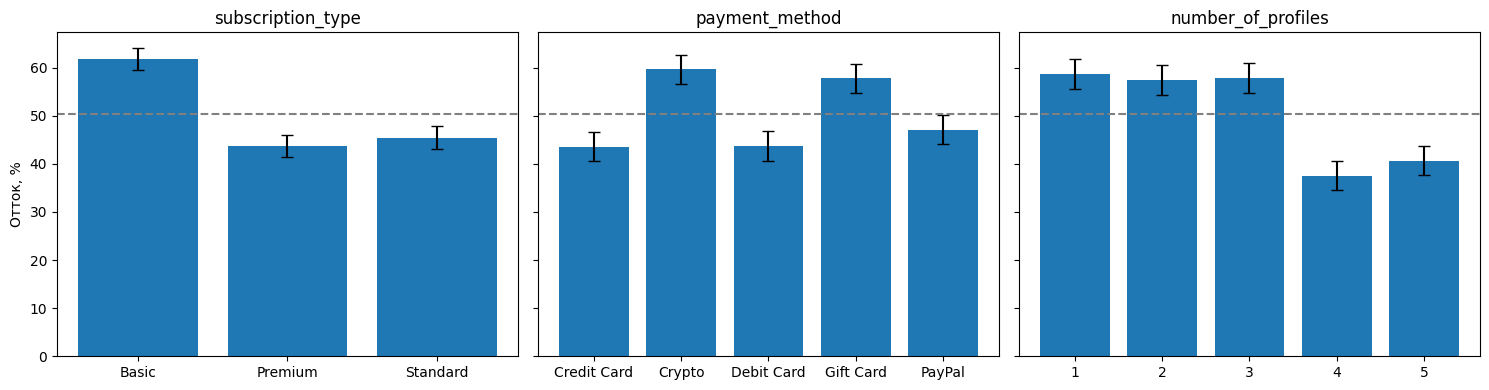

In [36]:
import matplotlib.pyplot as plt

def churn_ci(col):
    g = df_clean.groupby(col)["churned"].agg(["sum", "count"])
    g["rate"] = g["sum"] / g["count"]
    g["low"], g["high"] = proportion_confint(g["sum"], g["count"], method="wilson")
    return g

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, ["subscription_type", "payment_method", "number_of_profiles"]):
    g = churn_ci(col)
    ax.bar(g.index.astype(str), g["rate"] * 100,
           yerr=[(g["rate"] - g["low"]) * 100, (g["high"] - g["rate"]) * 100], capsize=4)
    ax.axhline(df_clean["churned"].mean() * 100, linestyle="--", color="gray")
    ax.set_title(col)
axes[0].set_ylabel("Отток, %")
plt.tight_layout()
plt.show()

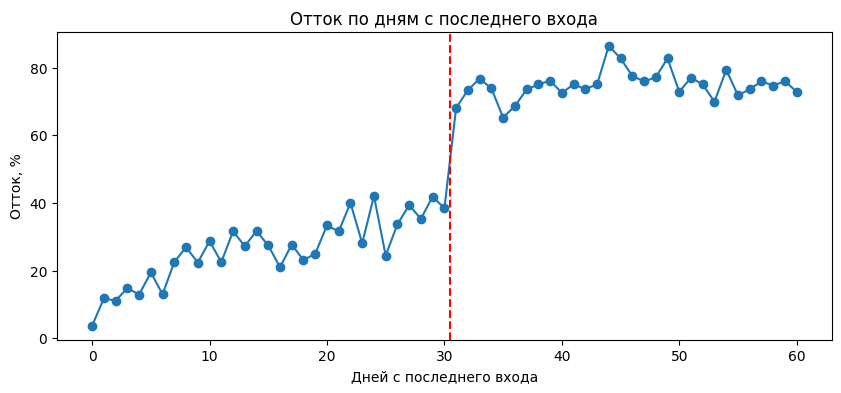

In [37]:
g = df_clean.groupby("last_login_days")["churned"].mean() * 100
plt.figure(figsize=(10, 4))
plt.plot(g.index, g.values, marker="o")
plt.axvline(30.5, linestyle="--", color="red")
plt.xlabel("Дней с последнего входа")
plt.ylabel("Отток, %")
plt.title("Отток по дням с последнего входа")
plt.show()

In [38]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report

num = ["age", "watch_hours", "last_login_days", "number_of_profiles"]
cat = ["subscription_type", "payment_method", "region", "device", "gender", "favorite_genre"]
X, y = df_clean[num + cat], df_clean["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

pre = ColumnTransformer([
    ("num", StandardScaler(), num),
    ("cat", OneHotEncoder(drop="first"), cat)])
model = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, model.predict(X_test)))

ROC-AUC: 0.961
              precision    recall  f1-score   support

           0       0.89      0.87      0.88       497
           1       0.88      0.89      0.88       503

    accuracy                           0.88      1000
   macro avg       0.88      0.88      0.88      1000
weighted avg       0.88      0.88      0.88      1000



****Результат очень хороший, и это подозрительно. В реальных данных об оттоке такие значения встречаются редко. Здесь данные синтетические и сгенерированы по правилам
last_login_days может быть следствием оттока, а не причиной. Тогда часть качества модели объясняется тем, что она узнаёт уже ушедших****

In [39]:
import numpy as np

names = model.named_steps["pre"].get_feature_names_out()
coefs = model.named_steps["clf"].coef_[0]
res = pd.DataFrame({"признак": names, "коэф": coefs, "odds_ratio": np.exp(coefs)})
print(res.sort_values("коэф").round(2).to_string(index=False))

                        признак  коэф  odds_ratio
               num__watch_hours -4.41        0.01
 cat__subscription_type_Premium -2.01        0.13
cat__subscription_type_Standard -1.99        0.14
        num__number_of_profiles -1.07        0.34
 cat__payment_method_Debit Card -0.27        0.76
cat__favorite_genre_Documentary -0.27        0.76
    cat__favorite_genre_Romance -0.18        0.83
               cat__gender_Male -0.15        0.86
     cat__favorite_genre_Sci-Fi -0.11        0.89
               cat__region_Asia -0.11        0.90
     cat__favorite_genre_Horror -0.11        0.90
              cat__gender_Other -0.10        0.90
     cat__payment_method_PayPal -0.07        0.93
      cat__region_North America -0.07        0.93
                       num__age -0.01        0.99
     cat__favorite_genre_Comedy  0.02        1.02
            cat__region_Oceania  0.04        1.04
             cat__device_Tablet  0.08        1.09
             cat__device_Mobile  0.10        1.10


In [40]:
lost = df_clean.loc[df_clean["churned"] == 1, "monthly_fee"].sum()
total = df_clean["monthly_fee"].sum()
print(f"Ушедшие клиенты платили ${lost:,.0f} из ${total:,.0f} в месяц ({lost/total:.0%})")

# Потери по тарифам
print(df_clean[df_clean["churned"] == 1].groupby("subscription_type")["monthly_fee"].agg(["count", "sum"]))

Ушедшие клиенты платили $33,010 из $68,417 в месяц (48%)
                   count       sum
subscription_type                 
Basic               1027   9232.73
Premium              740  13312.60
Standard             748  10464.52


In [41]:
active = df_clean[df_clean["churned"] == 0].copy()
active["risk"] = model.predict_proba(active[num + cat])[:, 1]

high = active[active["risk"] > 0.5]
print("Активных клиентов:", len(active))
print("С риском > 0.5:", len(high), " | платят в месяц: $", round(high["monthly_fee"].sum()))
print(high.groupby("subscription_type")["monthly_fee"].agg(["count", "sum"]).round(0))


Активных клиентов: 2485
С риском > 0.5: 275  | платят в месяц: $ 3807
                   count     sum
subscription_type               
Basic                 84   755.0
Premium               95  1709.0
Standard              96  1343.0
